#### Environmental and Operational Variabilities
<small>
CONTENT: Description of the definition of the EOVs applied 
</small>

#### Setup

In [1]:
# IMPORT
from math import *
import os
from statistics import *
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

In [2]:
# IMPORT
from math import *
import os
from statistics import *
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

In [3]:
# FOLDER
mainFolder = os.getcwd()
mainFolder = mainFolder.replace("\\", "/")
inputFolder = mainFolder + "/input"
outputFolder = mainFolder + "/output"

if not os.path.exists(inputFolder):
	os.makedirs(inputFolder)
if not os.path.exists(outputFolder):
	os.makedirs(outputFolder)

#### Define structural characteristics as input

In [4]:
# GEOMETRY
# units kg,m,s
# constants
g = 9.81 				# m/s²
# dimensions
L = 6 					# m - length from A to B
A_s = 30 				# m² - area of the slab supported by the beam
t_s = 0.18 				# m - thickness of the concrete slab
h = 400e-3 				# m - section height
b = 180e-3 				# m - flange width
t_w = 8.6e-3 			# m - web thickness
t_f = 13.5e-3 			# m - flange thickness
A_b = 84.46e-4 			# m² - cross-section IPE300
I_x = 23130e-8 			# m⁴ - strong inertia
W_el = I_x / (h/2) 		# m³ - elastic section moment
W_pl = 1307e-6			# m³ - plastic section moment
pLim = 29262e-3 * g / L # from kg to [kN/m] bending loading limit according to table for simply supported beam
print(f"Elastic section modulus (W_el): {W_el:.6f} m³")
print(f"Plastic section modulus (W_pl): {W_pl:.6f} m³")
print(f"Maximum bending load for simply supported IPE 400: {pLim:.2f} [kN/m]")

Elastic section modulus (W_el): 0.001156 m³
Plastic section modulus (W_pl): 0.001307 m³
Maximum bending load for simply supported IPE 400: 47.84 [kN/m]


In [5]:
# MATERIALS
E0 = 210e+9					# 210 GPa expressed in Pa = 1kg/ms² - Young’s modulus Steel
sigmaY = 235e+6				# N/m² - Yield strength steel S235	
yS = 1.05					# safety factor material properties
fyd = sigmaY / yS			# yield strength S235
M_r = W_el * sigmaY / yS 	# Nm - resisting moment
dS = 7850					# kg/m³ - Density Steel
dC = 2500					# kg/m³ - Density Concrete
print(f"Yiled strength S235: {fyd * 0.001:.2f} [kN/m²]")
print(f"Resisting moment IPE 400: {M_r * 0.001:.2f} [kNm]")

Yiled strength S235: 223809.52 [kN/m²]
Resisting moment IPE 400: 258.84 [kNm]


In [23]:
# TIMESERIES FOR PLOTS
start_date = datetime(2020,1,1,0,0,0) 		# Start date of recording: 01/01/2020 00:00
end_date = datetime(2022,12,31,23,0,0) 		# End date of recording: 31/12/2023 23:00
intVal = 1 									# Interval of acquisition
offsetAlias = 'H'							# Unit of measument of acquisition interval [hours]
tHourly = pd.date_range(start = start_date, end = end_date, freq = ('{}{}'.format(intVal, offsetAlias)))
# erase feb 29 in 2020 and 2024
timeSimulation = tHourly[~((tHourly.month == 2) & (tHourly.day == 29))]
daysMonitored = len(pd.Series(timeSimulation.date).unique())
end_datePlot = datetime(2023,1,1,0,1,0)

#### Calculate loads

In [7]:
# DISTRIBUTED LOAD
# permanent
pb = A_b * dS * g # N/m
ps = t_s * A_s * dC * g / L # N/m
pG1 = pb + ps
print(f"Self weight beam: {pb * 0.001:.2f} [kN/m]")
print(f"Self weight slab: {ps * 0.001:.2f} [kN/m]")
Pb = pb * L
Ps = ps * L
PG1 = Pb + Ps
print(f"Self weight beam: {Pb * 0.001:.2f} [kN]")
print(f"Self weight slab: {Ps * 0.001:.2f} [kN]")
pG2 = 1.2e+3 * A_s / L
PG2 = pG2 * L
print(f"Non structural permanent load: {pG2 * 0.001:.2f} [kN/m]")
print(f"Total structural permanent load: {(pb + ps) * 0.001:.2f} [kN/m]")
print(f"Total  permanent load: {(pb + ps + pG2) * 0.001:.2f} [kN/m]")
p = pb + ps + pG2
P = Pb + Ps + PG2
# Time invariant live-load reference
q1 = 3000 # N/m² - live-load (Eurocode 1 (EN 1991-1-1))
Q = q1 * A_s # N
q = Q /L # N/m
print(f"Time invariant Live Load: {q * 0.001:.2f} [kN/m]")
print(f"Ratio permanent:live: {p/q:.0f}:1 []")
gammaPSLE = 1.0
gammaQSLE = 1.0
Pdes_avgSLE = PG1 * gammaPSLE + PG2 * gammaPSLE + Q * gammaQSLE 	# average design point load for operational conditions including safety factor calculations [N]
pdes_avgSLE = Pdes_avgSLE /L	# average design distributed load for operational conditions including safety factor calculations [N/m]
print(f"Average design load SLE: {pdes_avgSLE* 0.001:.2f} [kN/m]")
gammaG1SLU = 1.3
gammaG2SLU = 1.5
gammaQSLU = 1.5
Pdes_avgSLU = PG1 * gammaG1SLU + PG2 * gammaG2SLU + Q * gammaQSLU 	# average design point load for operational conditions including safety factor calculations [N]
pdes_avgSLU = Pdes_avgSLU /L	# average design distributed load for operational conditions including safety factor calculations [N/m]
print(f"Average design load SLU: {pdes_avgSLU* 0.001:.2f} [kN/m]")

Self weight beam: 0.65 [kN/m]
Self weight slab: 22.07 [kN/m]
Self weight beam: 3.90 [kN]
Self weight slab: 132.44 [kN]
Non structural permanent load: 6.00 [kN/m]
Total structural permanent load: 22.72 [kN/m]
Total  permanent load: 28.72 [kN/m]
Time invariant Live Load: 15.00 [kN/m]
Ratio permanent:live: 2:1 []
Average design load SLE: 43.72 [kN/m]
Average design load SLU: 61.04 [kN/m]


In [8]:
# CHECKS
def deltaSS(p, L, E, I):
	# everything is in kg, m, s (N)
	# simply supported with distributed load (Euler Bernoulli)
	# check for extreme condition
	delta = (5 * p * L**4) / (384 * E * I) * 1000
	return delta

def deltaFF(p, L, E, I):
	# everything is in kg, m, s (N)
	# fixed fixed with distributed load (Euler Bernoulli)
	# check for extreme condition
	delta = (p * L**4) / (384 * E * I) * 1000
	return delta

deltaLimG = L / 250 * 1000 # [mm] rule of thumb for limit
deltaLimQ = L / 300 * 1000 # [mm] rule of thumb for limit
deltaOpG = deltaFF(p, L, E0, I_x)
deltaOpQ = deltaFF(q, L, E0, I_x)
if deltaOpG < deltaLimG and deltaOpQ < deltaLimQ:
	print("Deflection for design load: Verified")
else:
	print("Deflection for design load: Not verified")

# check section moment
M_aSLE = pdes_avgSLE * L**2 / 12 # fixed beam
M_aSLU = pdes_avgSLU * L**2 / 12 # fixed beam
if M_aSLE < M_r and M_aSLU < M_r:
	print("Section moment for design load: Verified")
else:
	print("Section moment for design load: Not verified")
print(f"Acting moment SLE: {M_aSLE * 0.001:.2f} [kNm]")
print(f"Acting moment SLU: {M_aSLU * 0.001:.2f} [kNm]")
print("Deflection limit G", deltaLimG)
print("Deflection design G", deltaOpG)
print("Deflection limit Q", deltaLimQ)
print("Deflection design Q", deltaOpQ)

Deflection for design load: Verified
Section moment for design load: Verified
Acting moment SLE: 131.17 [kNm]
Acting moment SLU: 183.12 [kNm]
Deflection limit G 24.0
Deflection design G 1.9957555441217343
Deflection limit Q 20.0
Deflection design Q 1.0422456920511396


In [9]:
# LIVE-LOAD TIME VARIANT
# parameters from JCSS
# sustained (long - term)
m_lt = 0.3 # NB. These are in kN/m2 now (JCSS value)
m_lt = 3 # Adjusted
factorVariance = 2
su = 0.15
su = su/factorVariance # Adjusted
sv = 0.3
sv = sv/factorVariance # Adjusted
k = 1
A0 = 20
Aratio = A0/A_s
# sustained load (long term)
s_lt = sqrt(su**2 + (sv**2 * k * Aratio))
lambda_lt = 0.1 # original should be 7
# intermitted (short term)
m_st = 0.3 # JCSS value
s_U = 0.4
s_U = s_U/factorVariance
s_st = sqrt(s_U**2 * k * Aratio)
ni_st = 1 # (concentration of people occuring 50 times per year)
ni_st = 5 # (concentration of people occuring 50 times per year) factorVariance
rho_st = 5 # (lasting 5 days)
# parameters of gamma distribution
alpha_lt = (m_lt / s_lt)** 2
theta_lt = s_lt** 2 / m_lt
alpha_st = (m_st / s_st) ** 2
theta_st = s_st** 2 / m_st

In [16]:
# SIMULATION INPUT
days = 365
hours = 24
years = 3
hours1year = days * hours
daysTot = days * years
timeSteps = days * hours * years
timeSeries = np.linspace(0, timeSteps-1, timeSteps)
time = np.arange(0, daysTot, 1/hours)

In [17]:
# GENERATION LIVE-LOAD
sustained_load = np.zeros_like(timeSeries)
intermitted_load = np.zeros_like(timeSeries)

# generate sustained load profile
current_time = 0
counter = 0
while current_time < timeSteps:
	# generate the next time interval for sustained load change
	interval = np.random.exponential(scale = lambda_lt) * 365 * 24
	# ensure the interval does not exceed one year
	if current_time + interval > timeSteps:
		interval = timeSteps - current_time # go back to the previou interval
	# generate the load intensity for this interval
	intensity = stats.gamma.rvs(a = alpha_lt, scale = theta_lt)
	# update the sustained load array for this interval
	sustained_load[(timeSeries >= current_time) & (timeSeries < current_time + interval)] = intensity
	# move to the next interval
	current_time += interval
	counter += 1
print("Intervals: ", counter)

# generate intermitted load profile
current_time = 0
counter = 0
while current_time < timeSteps:
	# generate the next time point for intermitted load
	interval = np.random.exponential(scale = 1/ni_st) * 365 * 24
	current_time += interval
	if current_time >= timeSteps:
		break
	# generate the load intensity for this point
	intensity = stats.gamma.rvs(a = alpha_st, scale = theta_st)
	# update the intermitted load array for this point with a fixed short duration
	intermitted_load[np.isclose(timeSeries, current_time, atol = rho_st)] = intensity
	counter += 1

print("Intervals: ", counter)


Intervals:  28
Intervals:  11


In [18]:
# TOTAL LOAD
# max and min live load separated
# note sustained and intermitted load are in kN/m2 from the JCSS data
maxSustained = ((max(sustained_load) * 10**(3) * A_s) /L ) # [kN/m] 
minSustained = ((min(sustained_load) * 10**(3) * A_s) /L )
maxIntermitted = ((max(intermitted_load) * 10**(3) * A_s) /L )
minIntermitted = ((min(intermitted_load) * 10**(3) * A_s) /L )

# transforming loads in N from kN/m2
liveLoadLt = sustained_load * 10**(3) * A_s # N
liveLoadSt = intermitted_load * 10**(3) * A_s # N
totalLiveLoad = liveLoadLt + liveLoadSt # N

# summing permanent load
# use safety factor calculations
permLoad = P
totalLoadSLU = PG1 * gammaG1SLU  + PG2 * gammaG2SLU + totalLiveLoad * gammaQSLU # N
totalLoadSLE = PG1 * gammaPSLE  + PG2 * gammaPSLE + totalLiveLoad * gammaQSLE # N

maxLoadLive = max(totalLiveLoad)/L # distributed only live N/m
minLoadLive = min(totalLiveLoad)/L # distributed only live 
avgLoadLive = mean(totalLiveLoad)/L # N/m

#(for equivalent mass calculations to sum to self-weight beam and slab mass)
maxLoadSLU = max(totalLoadSLU)/L
maxLoadSLE = max(totalLoadSLE)/L
minLoadSLU = min(totalLoadSLU)/L
minLoadSLE = min(totalLoadSLE)/L
maxPointLoadSLU = max(totalLoadSLU)
maxPointLoadSLE = max(totalLoadSLE)

def perc(part, whole):
	return (part / whole) * 100

print(f"Maximum sustained live load: {maxSustained * 0.001:.2f} [kN/m]")
print(f"Minimum sustainedlive load: {minSustained * 0.001:.2f} [kN/m]")
print(f"Maximum intermitted live load: {maxIntermitted * 0.001:.2f} [kN/m]")
print(f"Minimum intermitted live load: {minIntermitted * 0.001:.2f} [kN/m]")
print(f"Maximum live load: {maxLoadLive * 0.001:.2f} [kN/m]")
print(f"Minimum live load: {minLoadLive * 0.001:.2f} [kN/m]")
print(f"Average live load: {avgLoadLive * 0.001:.2f} [kN/m]")
print(f"Max Live = {perc(maxLoadLive,p):.1f} % permanent []")
print(f"Min Live = {perc(minLoadLive,p):.1f} % permanent []")
print(f"Avg Live = {perc(avgLoadLive,p):.1f} % permanent []")
print(f"Maximum total load slu: {maxLoadSLU * 0.001:.2f} [kN/m]")
print(f"Maximum total load sle: {maxLoadSLE * 0.001:.2f} [kN/m]")
print(f"Minimum total load slu: {minLoadSLU * 0.001:.2f} [kN/m]")
print(f"Minimum total load sle: {minLoadSLE * 0.001:.2f} [kN/m]")

Maximum sustained live load: 16.18 [kN/m]
Minimum sustainedlive load: 13.88 [kN/m]
Maximum intermitted live load: 3.19 [kN/m]
Minimum intermitted live load: 0.00 [kN/m]
Maximum live load: 19.26 [kN/m]
Minimum live load: 13.88 [kN/m]
Average live load: 14.96 [kN/m]
Max Live = 67.0 % permanent []
Min Live = 48.3 % permanent []
Avg Live = 52.1 % permanent []
Maximum total load slu: 67.42 [kN/m]
Maximum total load sle: 47.98 [kN/m]
Minimum total load slu: 59.36 [kN/m]
Minimum total load sle: 42.60 [kN/m]


In [19]:
# CHECKS 2
deltaLimG = L / 250 * 1000 # [mm] rule of thumb for limit
deltaLimQ = L / 300 * 1000 # [mm] rule of thumb for limit
deltaOpG = deltaFF(p, L, E0, I_x)
deltaOpQ = deltaFF(maxLoadLive, L, E0, I_x)
if deltaOpG < deltaLimG and deltaOpQ < deltaLimQ:
	print("Deflection for design load: Verified")
else:
	print("Deflection for design load: Not verified")

# check section moment
M_aSLE = maxLoadSLE * L**2 / 12 # fixed beam
M_aSLU = maxLoadSLU * L**2 / 12 # fixed beam
if M_aSLE < M_r and M_aSLU < M_r:
	print("Section moment for design load: Verified")
else:
	print("Section moment for design load: Not verified")
print(f"Acting moment SLE: {M_aSLE * 0.001:.2f} [kNm]")
print(f"Acting moment SLU: {M_aSLU * 0.001:.2f} [kNm]")
print("Deflection limit G", deltaLimG)
print("Deflection design G", deltaOpG)
print("Deflection limit Q", deltaLimQ)
print("Deflection design Q", deltaOpQ)

Deflection for design load: Verified
Section moment for design load: Verified
Acting moment SLE: 143.93 [kNm]
Acting moment SLU: 202.27 [kNm]
Deflection limit G 24.0
Deflection design G 1.9957555441217343
Deflection limit Q 20.0
Deflection design Q 1.3379246823659932


In [20]:
# MAXIMUM DEFLECTION
deltaOptemp = deltaFF(maxLoadSLU, L, E0, I_x)
print(f"Maximum deflection fixed beam: {deltaOptemp:.2f} [mm]")

Maximum deflection fixed beam: 4.68 [mm]


#### Plot load profiles

In [21]:
# CREATE DATAFRAME WITH LIVE LOADS AND TOTAL
totalloadDF = pd.DataFrame(data = totalLoadSLE, index = timeSimulation)
liveLTloadDF = pd.DataFrame(data = liveLoadLt, index = timeSimulation)
liveSTloadDF = pd.DataFrame(data = liveLoadSt, index = timeSimulation)
loadDF = pd.concat([totalloadDF,liveLTloadDF, liveSTloadDF], axis=1)
columnsNames = ["TotLoad", "LiveLoadLT", "LiveLoadST"]
loadDF.columns = columnsNames
loadDF.index.name = "Date"

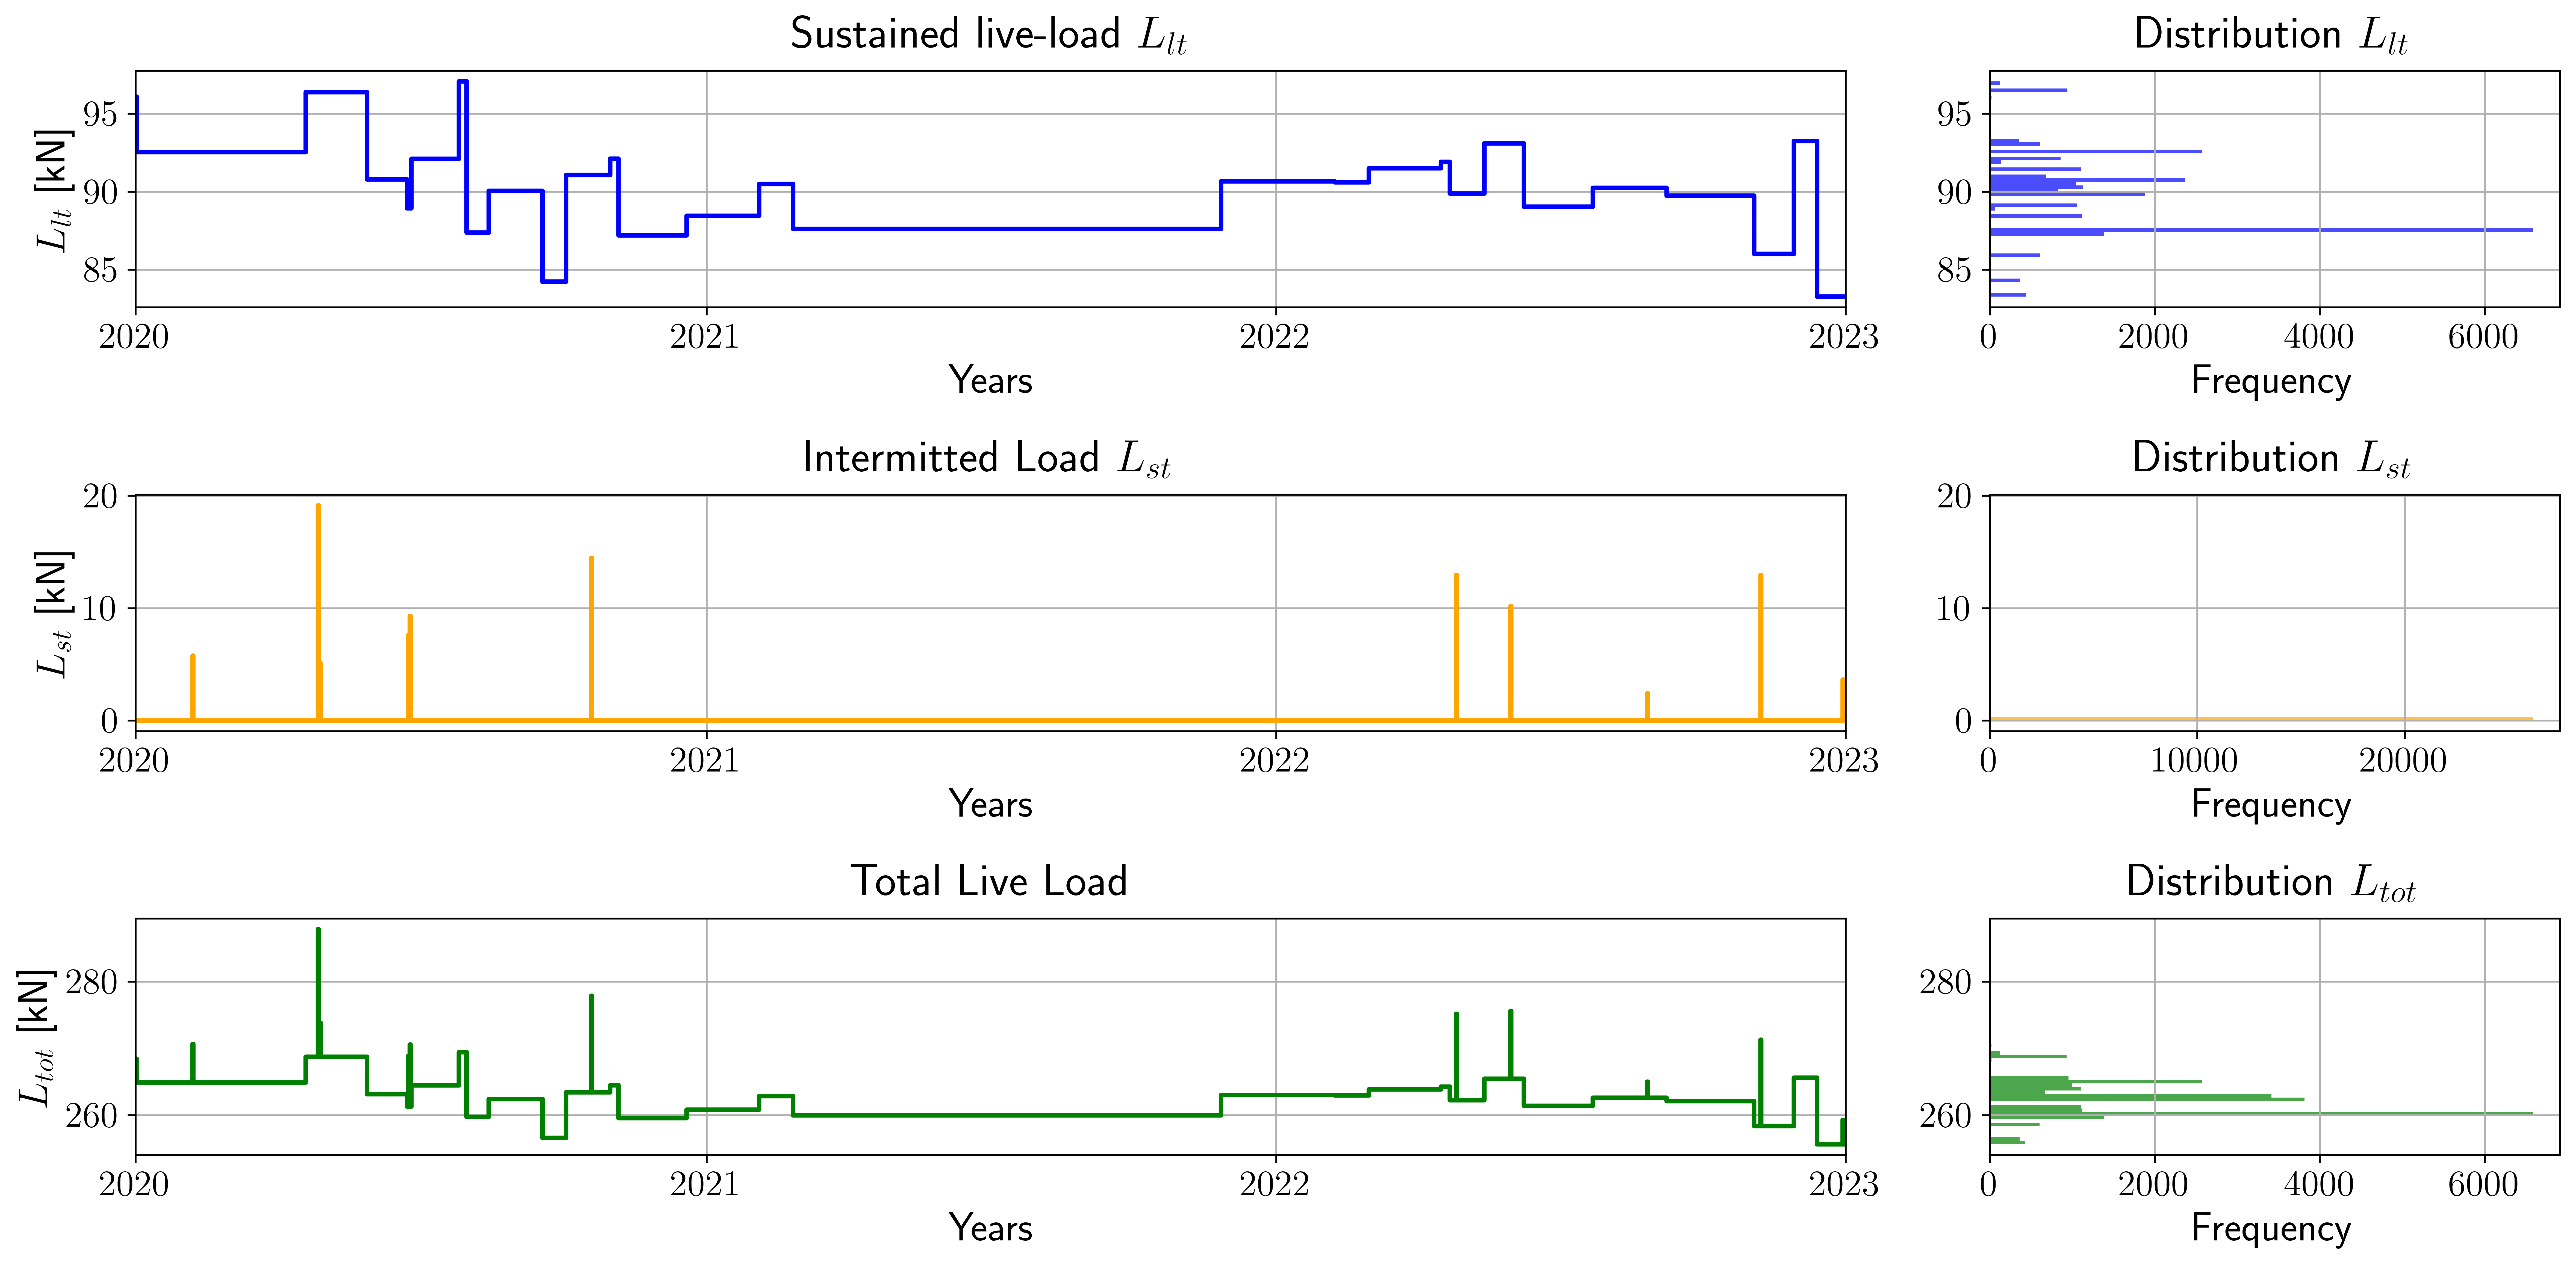

In [24]:
# PLOT LIVE LOAD COMPONENTS WITH DISTRIBUTIONS
totLiveLoad = totalLoadSLE

plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 600
plt.rcParams['font.size'] = 16

fig, ax = plt.subplots(3, 2, figsize = (16, 8), gridspec_kw = {'width_ratios': [3, 1]})

# sustained load time series
ax[0, 0].step(timeSimulation, liveLoadLt * 0.001, where='mid', color='blue', linewidth = 2)
ax[0, 0].set_title('Sustained live-load $L_{lt}$', fontsize = 20, pad = 10)
ax[0, 0].set_xlabel('Years', fontsize = 18)
ax[0, 0].set_ylabel('$L_{lt}$ [kN]', fontsize = 18)
ax[0, 0].set_xlim(timeSimulation[0], end_datePlot)
ax[0, 0].xaxis.set_major_locator(mdates.YearLocator(base = 1))
ax[0, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax[0, 0].grid(True)

# Sustained Load Distribution (KDE)
ax[0, 1].hist(liveLoadLt* 0.001, bins = 60, orientation = 'horizontal', color = 'blue', alpha = 0.7)
ax[0, 1].set_title('Distribution $L_{lt}$', fontsize = 20, pad = 10)
ax[0, 1].set_xlabel('Frequency', fontsize = 18)
ax[0, 1].grid(True)

# Intermitted Load Time Series
ax[1, 0].step(timeSimulation, liveLoadSt* 0.001, color = 'orange', linewidth = 2)
ax[1, 0].set_title('Intermitted Load $L_{st}$', fontsize = 20, pad = 10)
ax[1, 0].set_xlabel('Years', fontsize = 18)
ax[1, 0].set_ylabel('$L_{st}$ [kN]', fontsize = 18)
ax[1, 0].set_xlim(timeSimulation[0], end_datePlot)
ax[1, 0].xaxis.set_major_locator(mdates.YearLocator(base = 1))
ax[1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax[1, 0].grid(True)


# Intermitted Load Distribution (KDE)
ax[1, 1].hist(liveLoadSt* 0.001, bins = 60, orientation = 'horizontal', color = 'orange', alpha = 0.7)
ax[1, 1].set_title('Distribution $L_{st}$', fontsize = 20, pad = 10)
ax[1, 1].set_xlabel('Frequency', fontsize = 18)
ax[1, 1].grid(True)

# Total Load Time Series
ax[2, 0].step(timeSimulation, totLiveLoad* 0.001, color = 'green', linewidth = 2)
ax[2, 0].set_title('Total Live Load', fontsize = 20, pad = 10)
ax[2, 0].set_xlabel('Years', fontsize = 18)
ax[2, 0].set_ylabel('$L_{tot}$ [kN]', fontsize = 18)
ax[2, 0].set_xlim(timeSimulation[0], end_datePlot)
ax[2, 0].xaxis.set_major_locator(mdates.YearLocator(base = 1))
ax[2, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax[2, 0].grid(True)

# Total Load Distribution (KDE)
ax[2, 1].hist(totLiveLoad* 0.001, bins = 60, orientation = 'horizontal', color = 'green', alpha = 0.7)
ax[2, 1].set_title('Distribution $L_{tot}$', fontsize = 20, pad = 10)
ax[2, 1].set_xlabel('Frequency', fontsize = 18)
ax[2, 1].grid(True)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [25]:
# EQUIVALENT MASS
maxLoad = max(totalLoadSLE) # N
minLoad = min(totalLoadSLE) # N
avgLoad = mean(totalLoadSLE) # N
mTotMax = (maxLoad) / g # kg or [N s^2 /m]
mTotMin = (minLoad) / g # kg
mTotAvg = (avgLoad) / g # kg
print(f"Maximum total mass: {mTotMax/1000:.2f} [kN s^2 /m] or [tons]")
print(f"Minimum total mass: {mTotMin/1000:.2f} [kN s^2 /m] or [tons]")
print(f"Average total mass: {mTotAvg/1000:.2f} [kN s^2 /m] or [tons]")

Maximum total mass: 29.34 [kN s^2 /m] or [tons]
Minimum total mass: 26.06 [kN s^2 /m] or [tons]
Average total mass: 26.72 [kN s^2 /m] or [tons]


In [26]:
# EQUIVALENT STIFFNESS
# Calculating Stiffness
k_ff = (384 * E0 * I_x) / (L**3)	# Fixed fixed with uniform load
k_fp = (192 * E0 * I_x) / (L**3)	# Fixed pinned with uniform load
k_ss = (48 * E0 * I_x) / (L**3)		# Simply supported with uniform load

# Average natural frequency
omega_n = np.sqrt(k_ff / mTotAvg)  # Natural frequency in rad/s
f_n = omega_n / (2 * np.pi)  # Convert to Hz
print(f"Average angular frequency: {omega_n:.3f} [Hz]")
print(f"Average natural frequency: {f_n:.3f} [Hz]")
zeta = 0.05  # Damping ratio
omega_d = omega_n * np.sqrt(1 - zeta**2)
f_d = omega_d / (2 * np.pi)  # Convert to Hz
print(f"Average damped angular  frequency: {omega_d:.3f} [Hz]")
print(f"Average damped natural frequency: {f_d:.3f} [Hz]")

print(f"Bending stiffness: {k_ff * 0.001:.3f} [kN/m]")

cavg = 2 * zeta * mTotAvg * omega_n 
print(f"Avg damping coeffient: {cavg * 0.001:.3f} []")

Average angular frequency: 56.849 [Hz]
Average natural frequency: 9.048 [Hz]
Average damped angular  frequency: 56.778 [Hz]
Average damped natural frequency: 9.036 [Hz]
Bending stiffness: 86352.000 [kN/m]
Avg damping coeffient: 151.897 []


In [27]:
# CHECK OVs IMPACT ON FREQUENCIES
omega_n_MaxOVs = np.sqrt(k_ff / mTotMax)  # Natural frequency in rad/s
omega_n_MinOVs = np.sqrt(k_ff / mTotMin)  # Natural frequency in rad/s
omega_n_AvgOVs = np.sqrt(k_ff / mTotAvg)  # Natural frequency in rad/s

f_n_MaxOVs = omega_n_MaxOVs / (2 * np.pi)  # Convert to Hz
f_n_MinOVs = omega_n_MinOVs / (2 * np.pi)  # Convert to Hz
deltaF_OVs = f_n_MinOVs - f_n_MaxOVs
def perc(part, whole):
	return (part / whole) * 100

deltaF_OVs_perc = perc(deltaF_OVs, f_n_MinOVs)
print(f"Frequency percentage decrease due to variability in OVs: {-deltaF_OVs_perc:.2f}%")

Frequency percentage decrease due to variability in OVs: -5.77%


In [ ]:
# SAVE LOAD TO FILE
output_file = inputFolder + '/load/1_totLoad.txt'
with open(output_file, 'w') as file:
	loadDF.to_csv(file, sep = '\t', index = True, header = True)

#### Load temperature profiles

In [ ]:
# LOAD TEMPERATURE DATA FROM CVS
temperatureFolder = inputFolder + "/temperature"
csvFilesTemp = [f for f in os.listdir(temperatureFolder) if f.endswith('.csv')]

temperatureData = pd.DataFrame()
for i in range(len(csvFilesTemp)):
	filePath = os.path.join(temperatureFolder, csvFilesTemp[i])
	dfTemp = pd.read_csv(filePath, delimiter = ';', decimal = ',')
	temperatureData = pd.concat((temperatureData, dfTemp), axis = 0)

temperatureData.index = pd.to_datetime(temperatureData["Date"], format = "%d/%m/%Y %H:%M")
temperatureData = temperatureData.drop(columns = "Date")
temperatureData.head()
hourlyTemp = temperatureData.resample('H').mean()

maskBisestile = ~((hourlyTemp.index.month == 2) & (hourlyTemp.index.day == 29))
# filter out February 29th
hourlyTemp = hourlyTemp[maskBisestile]

In [ ]:
# SAVE RESAMPLED TEMPERATURE TO FILE
output_file = inputFolder + '/temperature/1_temperature.txt'
with open(output_file, 'w') as file:
	hourlyTemp.to_csv(file, sep = '\t', index = True, header = True)